In [3]:
# Load source data and configure project paths
# Configure project paths, load source data and define reusable helpers

import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Locate project root
current_path = Path.cwd()
PROJECT_DIR = None

for candidate in [current_path] + list(current_path.parents):
    raw_folder = candidate / "data" / "raw"
    if raw_folder.exists() and list(raw_folder.glob("Nassau Candy Distributor*.csv")):
        PROJECT_DIR = candidate
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Project folder not found. Open Jupyter inside Nassau_Candy_Final_Submission."
    )

# Configure folders
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports" / "profitability_sensitivity"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

for folder in [PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Locate original CSV
raw_candidates = list(RAW_DIR.glob("Nassau Candy Distributor*.csv"))

if not raw_candidates:
    raise FileNotFoundError("Original Nassau Candy Distributor CSV not found.")

RAW_FILE = raw_candidates[0]

# Load a separate working copy
df_profit = pd.read_csv(RAW_FILE)

# Required source columns
required_columns = [
    "Row ID", "Order ID", "Order Date", "Product Name",
    "Division", "Region", "Sales", "Units",
    "Gross Profit", "Cost"
]

missing_columns = [
    col for col in required_columns
    if col not in df_profit.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Validate numeric fields
numeric_columns = ["Sales", "Units", "Gross Profit", "Cost"]

for col in numeric_columns:
    df_profit[col] = pd.to_numeric(df_profit[col], errors="raise")

if (df_profit["Sales"] < 0).any():
    print("Warning: Negative sales values detected. They will be retained.")

# Record source file hash
def calculate_sha256(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(block)
    return sha256.hexdigest()

ORIGINAL_CSV_HASH = calculate_sha256(RAW_FILE)

# Store source snapshot for integrity comparison
original_row_count = len(df_profit)
original_columns = list(df_profit.columns)

print(" setup completed.")
print("Project:", PROJECT_DIR)
print("Source dataset shape:", df_profit.shape)
print("Unique products:", df_profit["Product Name"].nunique())
print("Original CSV hash:", ORIGINAL_CSV_HASH)

 setup completed.
Project: C:\Users\hp\Nassau_Candy_Final_Submission
Source dataset shape: (10194, 18)
Unique products: 15
Original CSV hash: 6ae9208e77ce410e90073b19813d29f89853ce9f3cce43d41f9643781696e94f


In [5]:
# Historical sales baseline
# Calculate historical sales baseline

sales_baseline = pd.DataFrame([{
    "Order_Lines": len(df_profit),
    "Unique_Orders": df_profit["Order ID"].nunique(),
    "Unique_Products": df_profit["Product Name"].nunique(),
    "Total_Sales": df_profit["Sales"].sum(),
    "Average_Sales_Per_Line": df_profit["Sales"].mean(),
    "Median_Sales_Per_Line": df_profit["Sales"].median(),
    "Minimum_Sales_Per_Line": df_profit["Sales"].min(),
    "Maximum_Sales_Per_Line": df_profit["Sales"].max()
}])

sales_baseline.to_csv(
    PROCESSED_DIR / "historical_sales_baseline.csv",
    index=False
)

display(sales_baseline)
print("Historical sales baseline saved.")

,Order_Lines,Unique_Orders,Unique_Products,Total_Sales,Average_Sales_Per_Line,Median_Sales_Per_Line,Minimum_Sales_Per_Line,Maximum_Sales_Per_Line
0,10194,8549,15,141783.63,13.908537,10.8,1.25,260.0


Historical sales baseline saved.


In [7]:
# Historical cost baseline
# Calculate historical cost baseline

cost_baseline = pd.DataFrame([{
    "Order_Lines": len(df_profit),
    "Total_Cost": df_profit["Cost"].sum(),
    "Average_Cost_Per_Line": df_profit["Cost"].mean(),
    "Median_Cost_Per_Line": df_profit["Cost"].median(),
    "Minimum_Cost_Per_Line": df_profit["Cost"].min(),
    "Maximum_Cost_Per_Line": df_profit["Cost"].max(),
    "Total_Units": df_profit["Units"].sum(),
    "Cost_Per_Unit": (
        df_profit["Cost"].sum() / df_profit["Units"].sum()
        if df_profit["Units"].sum() != 0 else np.nan
    )
}])

cost_baseline.to_csv(
    PROCESSED_DIR / "historical_cost_baseline.csv",
    index=False
)

display(cost_baseline)
print("Historical cost baseline saved.")

,Order_Lines,Total_Cost,Average_Cost_Per_Line,Median_Cost_Per_Line,Minimum_Cost_Per_Line,Maximum_Cost_Per_Line,Total_Units,Cost_Per_Unit
0,10194,48340.83,4.742087,3.6,0.6,130.0,38654,1.250604


Historical cost baseline saved.


In [9]:
# Historical gross profit baseline
# Calculate historical gross profit baseline

total_sales = df_profit["Sales"].sum()
total_cost = df_profit["Cost"].sum()
total_gross_profit = df_profit["Gross Profit"].sum()

gross_profit_baseline = pd.DataFrame([{
    "Order_Lines": len(df_profit),
    "Total_Sales": total_sales,
    "Total_Cost": total_cost,
    "Total_Gross_Profit": total_gross_profit,
    "Aggregate_Gross_Profit_Margin_Pct": (
        total_gross_profit / total_sales * 100
        if total_sales != 0 else np.nan
    ),
    "Sales_Minus_Cost": total_sales - total_cost,
    "Gross_Profit_Reconciliation_Difference": (
        total_gross_profit - (total_sales - total_cost)
    )
}])

gross_profit_baseline.to_csv(
    PROCESSED_DIR / "historical_gross_profit_baseline.csv",
    index=False
)

display(gross_profit_baseline)

print("Historical gross profit baseline saved.")
print(
    "Note: Gross Profit is retained as supplied by the original dataset. "
    "Any difference from Sales minus Cost is reported, not silently corrected."
)

,Order_Lines,Total_Sales,Total_Cost,Total_Gross_Profit,Aggregate_Gross_Profit_Margin_Pct,Sales_Minus_Cost,Gross_Profit_Reconciliation_Difference
0,10194,141783.63,48340.83,93442.8,65.905211,93442.8,0.0


Historical gross profit baseline saved.
Note: Gross Profit is retained as supplied by the original dataset. Any difference from Sales minus Cost is reported, not silently corrected.


In [11]:
# Product-wise profit margin
# Calculate product-wise gross profit and margin

product_margin = (
    df_profit.groupby("Product Name", as_index=False)
    .agg(
        Order_Lines=("Row ID", "count"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Total_Cost=("Cost", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
)

product_margin["Gross_Profit_Margin_Pct"] = np.where(
    product_margin["Total_Sales"] != 0,
    product_margin["Total_Gross_Profit"]
    / product_margin["Total_Sales"] * 100,
    np.nan
)

product_margin["Gross_Profit_Per_Unit"] = np.where(
    product_margin["Total_Units"] != 0,
    product_margin["Total_Gross_Profit"]
    / product_margin["Total_Units"],
    np.nan
)

product_margin = product_margin.sort_values(
    "Gross_Profit_Margin_Pct",
    ascending=False
)

product_margin.to_csv(
    PROCESSED_DIR / "product_wise_profit_margin.csv",
    index=False
)

display(product_margin)
print("Product-wise margin report saved.")

,Product Name,Order_Lines,Total_Units,Total_Sales,Total_Cost,Total_Gross_Profit,Gross_Profit_Margin_Pct,Gross_Profit_Per_Unit
0,Everlasting Gobstopper,3,13,130.00,26.00,104.00,80.000000,8.00
3,Hair Toffee,4,17,76.50,17.00,59.50,77.777778,3.50
11,Wonka Bar - Nutty Crunch Surprise,1810,6755,23574.95,6755.00,16819.95,71.346705,2.49
13,Wonka Bar -Scrumdiddlyumptious,2064,7743,27874.80,8517.30,19357.50,69.444444,2.50
9,Wonka Bar - Fudge Mallows,1818,6914,24890.40,8296.80,16593.60,66.666667,2.40
12,Wonka Bar - Triple Dazzle Caramel,2015,7596,28485.00,9874.80,18610.20,65.333333,2.45
10,Wonka Bar - Milk Chocolate,2137,8267,26867.75,9424.38,17443.37,64.923077,2.11
5,Laffy Taffy,10,27,53.73,20.25,33.48,62.311558,1.24
1,Fizzy Lifting Drinks,6,21,78.75,31.50,47.25,60.000000,2.25
14,Wonka Gum,120,478,597.50,286.80,310.70,52.000000,0.65


Product-wise margin report saved.


In [13]:
# Division-wise profit margin
# Calculate division-wise gross profit and margin

division_margin = (
    df_profit.groupby("Division", as_index=False)
    .agg(
        Order_Lines=("Row ID", "count"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Total_Cost=("Cost", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
)

division_margin["Gross_Profit_Margin_Pct"] = np.where(
    division_margin["Total_Sales"] != 0,
    division_margin["Total_Gross_Profit"]
    / division_margin["Total_Sales"] * 100,
    np.nan
)

division_margin.to_csv(
    PROCESSED_DIR / "division_wise_profit_margin.csv",
    index=False
)

display(division_margin)
print("Division-wise margin report saved.")

,Division,Order_Lines,Total_Units,Total_Sales,Total_Cost,Total_Gross_Profit,Gross_Profit_Margin_Pct
0,Chocolate,9844,37275,131692.90,42868.28,88824.62,67.448298
1,Other,310,1242,9663.25,5329.80,4333.45,44.844643
2,Sugar,40,137,427.48,142.75,284.73,66.606625


Division-wise margin report saved.


In [15]:
# Region-wise profit margin
# Calculate region-wise gross profit and margin

region_margin = (
    df_profit.groupby("Region", as_index=False)
    .agg(
        Order_Lines=("Row ID", "count"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Total_Cost=("Cost", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
)

region_margin["Gross_Profit_Margin_Pct"] = np.where(
    region_margin["Total_Sales"] != 0,
    region_margin["Total_Gross_Profit"]
    / region_margin["Total_Sales"] * 100,
    np.nan
)

region_margin.to_csv(
    PROCESSED_DIR / "region_wise_profit_margin.csv",
    index=False
)

display(region_margin)
print("Region-wise margin report saved.")

,Region,Order_Lines,Total_Units,Total_Sales,Total_Cost,Total_Gross_Profit,Gross_Profit_Margin_Pct
0,Atlantic,2986,11159,41197.24,14223.54,26973.70,65.474532
1,Gulf,1620,6209,22247.26,7546.59,14700.67,66.078564
2,Interior,2335,8820,32037.60,10755.11,21282.49,66.429726
3,Pacific,3253,12466,46301.53,15815.59,30485.94,65.842187


Region-wise margin report saved.


In [17]:
# Profit variability
# This task measures variation in line-level gross profit. It is descriptive and does not establish the cause of profit changes.
# Measure historical gross profit variability by product

profit_variability = (
    df_profit.groupby("Product Name", as_index=False)
    .agg(
        Order_Lines=("Gross Profit", "count"),
        Mean_Gross_Profit=("Gross Profit", "mean"),
        Median_Gross_Profit=("Gross Profit", "median"),
        Std_Gross_Profit=("Gross Profit", "std"),
        Minimum_Gross_Profit=("Gross Profit", "min"),
        Maximum_Gross_Profit=("Gross Profit", "max"),
        Gross_Profit_IQR=(
            "Gross Profit",
            lambda x: x.quantile(0.75) - x.quantile(0.25)
        )
    )
)

profit_variability["Gross_Profit_CV_Pct"] = np.where(
    profit_variability["Mean_Gross_Profit"] != 0,
    profit_variability["Std_Gross_Profit"].abs()
    / profit_variability["Mean_Gross_Profit"].abs() * 100,
    np.nan
)

profit_variability["Interpretation"] = (
    "Descriptive variability of historical order-line gross profit"
)

profit_variability.to_csv(
    PROCESSED_DIR / "profit_variability_report.csv",
    index=False
)

display(
    profit_variability.sort_values(
        "Std_Gross_Profit",
        ascending=False
    )
)

print("Profit variability report saved.")

,Product Name,Order_Lines,Mean_Gross_Profit,Median_Gross_Profit,Std_Gross_Profit,Minimum_Gross_Profit,Maximum_Gross_Profit,Gross_Profit_IQR,Gross_Profit_CV_Pct,Interpretation
6,Lickable Wallpaper,94,41.808511,40.000,24.272767,10.00,130.00,30.000,58.057001,Descriptive variability of historical order-li...
0,Everlasting Gobstopper,3,34.666667,32.000,12.220202,24.00,48.00,12.000,35.250582,Descriptive variability of historical order-li...
13,Wonka Bar -Scrumdiddlyumptious,2064,9.378634,7.500,5.565864,2.50,35.00,7.500,59.346212,Descriptive variability of historical order-li...
12,Wonka Bar - Triple Dazzle Caramel,2015,9.235831,7.350,5.423458,2.45,34.30,7.350,58.721929,Descriptive variability of historical order-li...
11,Wonka Bar - Nutty Crunch Surprise,1810,9.292790,7.470,5.404772,2.49,34.86,7.470,58.160916,Descriptive variability of historical order-li...
9,Wonka Bar - Fudge Mallows,1818,9.127393,7.200,5.273759,2.40,33.60,7.200,57.779469,Descriptive variability of historical order-li...
3,Hair Toffee,4,14.875000,17.500,5.250000,7.00,17.50,2.625,35.294118,Descriptive variability of historical order-li...
10,Wonka Bar - Milk Chocolate,2137,8.162550,6.330,4.859998,2.11,29.54,6.330,59.540189,Descriptive variability of historical order-li...
1,Fizzy Lifting Drinks,6,7.875000,7.875,2.359820,4.50,11.25,2.250,29.965967,Descriptive variability of historical order-li...
5,Laffy Taffy,10,3.348000,2.480,2.191057,1.24,7.44,3.100,65.443745,Descriptive variability of historical order-li...


Profit variability report saved.


In [19]:
# Margin stability proxy
#This measures the variation in order-line gross profit margins for each product. It is a stability proxy, not a formal statistical risk estimate.
# Calculate product-level margin stability proxy

df_margin_stability = df_profit.copy()

df_margin_stability["Line_Margin_Pct"] = np.where(
    df_margin_stability["Sales"] != 0,
    df_margin_stability["Gross Profit"]
    / df_margin_stability["Sales"] * 100,
    np.nan
)

margin_stability = (
    df_margin_stability.groupby("Product Name", as_index=False)
    .agg(
        Order_Lines=("Line_Margin_Pct", "count"),
        Mean_Line_Margin_Pct=("Line_Margin_Pct", "mean"),
        Median_Line_Margin_Pct=("Line_Margin_Pct", "median"),
        Std_Line_Margin_Pct=("Line_Margin_Pct", "std"),
        Minimum_Line_Margin_Pct=("Line_Margin_Pct", "min"),
        Maximum_Line_Margin_Pct=("Line_Margin_Pct", "max"),
        Margin_IQR_Pct=(
            "Line_Margin_Pct",
            lambda x: x.quantile(0.75) - x.quantile(0.25)
        )
    )
)

margin_stability["Margin_Stability_Proxy"] = np.where(
    margin_stability["Std_Line_Margin_Pct"].notna(),
    1 / (1 + margin_stability["Std_Line_Margin_Pct"].abs()),
    np.nan
)

margin_stability["Interpretation"] = (
    "Higher proxy indicates lower observed line-margin standard deviation; "
    "not a forecast or causal stability measure"
)

margin_stability.to_csv(
    PROCESSED_DIR / "margin_stability_proxy.csv",
    index=False
)

display(
    margin_stability.sort_values(
        "Std_Line_Margin_Pct",
        ascending=True
    )
)

print("Margin stability proxy report saved.")

,Product Name,Order_Lines,Mean_Line_Margin_Pct,Median_Line_Margin_Pct,Std_Line_Margin_Pct,Minimum_Line_Margin_Pct,Maximum_Line_Margin_Pct,Margin_IQR_Pct,Margin_Stability_Proxy,Interpretation
0,Everlasting Gobstopper,3,80.000000,80.000000,0.000000e+00,80.000000,80.000000,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
1,Fizzy Lifting Drinks,6,60.000000,60.000000,0.000000e+00,60.000000,60.000000,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
2,Fun Dip,3,40.000000,40.000000,0.000000e+00,40.000000,40.000000,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
3,Hair Toffee,4,77.777778,77.777778,0.000000e+00,77.777778,77.777778,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
4,Kazookles,96,7.692308,7.692308,0.000000e+00,7.692308,7.692308,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
5,Laffy Taffy,10,62.311558,62.311558,0.000000e+00,62.311558,62.311558,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
6,Lickable Wallpaper,94,50.000000,50.000000,0.000000e+00,50.000000,50.000000,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
7,Nerds,4,46.666667,46.666667,0.000000e+00,46.666667,46.666667,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
8,SweeTARTS,10,46.666667,46.666667,0.000000e+00,46.666667,46.666667,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...
11,Wonka Bar - Nutty Crunch Surprise,1810,71.346705,71.346705,0.000000e+00,71.346705,71.346705,0.000000e+00,1.0,Higher proxy indicates lower observed line-mar...


Margin stability proxy report saved.


In [21]:
# Identify high-profit products
# Ranking is based on total historical gross profit, not margin percentage. These are different measures.
# Rank products by total historical gross profit

high_profit_products = product_margin[
    [
        "Product Name",
        "Order_Lines",
        "Total_Units",
        "Total_Sales",
        "Total_Gross_Profit",
        "Gross_Profit_Margin_Pct"
    ]
].copy()

high_profit_products = high_profit_products.sort_values(
    "Total_Gross_Profit",
    ascending=False
).reset_index(drop=True)

high_profit_products.insert(
    0,
    "Profit_Rank",
    range(1, len(high_profit_products) + 1)
)

high_profit_products["Ranking_Basis"] = (
    "Total historical gross profit"
)

high_profit_products.to_csv(
    PROCESSED_DIR / "high_profit_product_ranking.csv",
    index=False
)

display(high_profit_products)

print("High-profit product ranking saved.")

,Profit_Rank,Product Name,Order_Lines,Total_Units,Total_Sales,Total_Gross_Profit,Gross_Profit_Margin_Pct,Ranking_Basis
0,1,Wonka Bar -Scrumdiddlyumptious,2064,7743,27874.80,19357.50,69.444444,Total historical gross profit
1,2,Wonka Bar - Triple Dazzle Caramel,2015,7596,28485.00,18610.20,65.333333,Total historical gross profit
2,3,Wonka Bar - Milk Chocolate,2137,8267,26867.75,17443.37,64.923077,Total historical gross profit
3,4,Wonka Bar - Nutty Crunch Surprise,1810,6755,23574.95,16819.95,71.346705,Total historical gross profit
4,5,Wonka Bar - Fudge Mallows,1818,6914,24890.40,16593.60,66.666667,Total historical gross profit
5,6,Lickable Wallpaper,94,393,7860.00,3930.00,50.000000,Total historical gross profit
6,7,Wonka Gum,120,478,597.50,310.70,52.000000,Total historical gross profit
7,8,Everlasting Gobstopper,3,13,130.00,104.00,80.000000,Total historical gross profit
8,9,Kazookles,96,371,1205.75,92.75,7.692308,Total historical gross profit
9,10,Hair Toffee,4,17,76.50,59.50,77.777778,Total historical gross profit


High-profit product ranking saved.


In [23]:
# Identify low-margin products
# This creates a relative risk list by ranking products from lowest to highest aggregate margin. 
# It does not impose an invented universal margin threshold.
# Identify products with comparatively low historical gross profit margins

low_margin_products = product_margin[
    [
        "Product Name",
        "Order_Lines",
        "Total_Sales",
        "Total_Gross_Profit",
        "Gross_Profit_Margin_Pct"
    ]
].copy()

low_margin_products = low_margin_products.dropna(
    subset=["Gross_Profit_Margin_Pct"]
)

low_margin_products = low_margin_products.sort_values(
    "Gross_Profit_Margin_Pct",
    ascending=True
).reset_index(drop=True)

low_margin_products.insert(
    0,
    "Low_Margin_Rank",
    range(1, len(low_margin_products) + 1)
)

low_margin_products["Risk_Interpretation"] = (
    "Relative low-margin position; not proof of financial distress"
)

low_margin_products.to_csv(
    PROCESSED_DIR / "low_margin_product_risk_list.csv",
    index=False
)

display(low_margin_products)

print("Low-margin product risk list saved.")

,Low_Margin_Rank,Product Name,Order_Lines,Total_Sales,Total_Gross_Profit,Gross_Profit_Margin_Pct,Risk_Interpretation
0,1,Kazookles,96,1205.75,92.75,7.692308,Relative low-margin position; not proof of fin...
1,2,Fun Dip,3,12.00,4.80,40.000000,Relative low-margin position; not proof of fin...
2,3,Nerds,4,15.00,7.00,46.666667,Relative low-margin position; not proof of fin...
3,4,SweeTARTS,10,61.50,28.70,46.666667,Relative low-margin position; not proof of fin...
4,5,Lickable Wallpaper,94,7860.00,3930.00,50.000000,Relative low-margin position; not proof of fin...
5,6,Wonka Gum,120,597.50,310.70,52.000000,Relative low-margin position; not proof of fin...
6,7,Fizzy Lifting Drinks,6,78.75,47.25,60.000000,Relative low-margin position; not proof of fin...
7,8,Laffy Taffy,10,53.73,33.48,62.311558,Relative low-margin position; not proof of fin...
8,9,Wonka Bar - Milk Chocolate,2137,26867.75,17443.37,64.923077,Relative low-margin position; not proof of fin...
9,10,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,18610.20,65.333333,Relative low-margin position; not proof of fin...


Low-margin product risk list saved.


In [25]:
# Create hypothetical freight cost input
# The input is an additional freight cost per unit, expressed in the same monetary units as the dataset. 
# Blank user assumptions remain blank and are not treated as zero.
# Create editable hypothetical freight cost assumptions

FREIGHT_ASSUMPTIONS_FILE = (
    PROCESSED_DIR / "hypothetical_freight_cost_input.csv"
)

if not FREIGHT_ASSUMPTIONS_FILE.exists():

    freight_template = pd.DataFrame([
        {
            "Scenario_ID": "BASELINE",
            "Scenario_Name": "Historical baseline",
            "Additional_Freight_Cost_Per_Unit": 0.0,
            "Assumption_Source": "No hypothetical adjustment"
        },
        {
            "Scenario_ID": "FREIGHT_01",
            "Scenario_Name": "User freight scenario 1",
            "Additional_Freight_Cost_Per_Unit": np.nan,
            "Assumption_Source": "Enter a user-supplied assumption"
        },
        {
            "Scenario_ID": "FREIGHT_02",
            "Scenario_Name": "User freight scenario 2",
            "Additional_Freight_Cost_Per_Unit": np.nan,
            "Assumption_Source": "Enter a user-supplied assumption"
        },
        {
            "Scenario_ID": "FREIGHT_03",
            "Scenario_Name": "User freight scenario 3",
            "Additional_Freight_Cost_Per_Unit": np.nan,
            "Assumption_Source": "Enter a user-supplied assumption"
        }
    ])

    freight_template.to_csv(
        FREIGHT_ASSUMPTIONS_FILE,
        index=False
    )

freight_assumptions = pd.read_csv(
    FREIGHT_ASSUMPTIONS_FILE
)

display(freight_assumptions)

print("Freight assumptions file:")
print(FREIGHT_ASSUMPTIONS_FILE)

print(
    "\nEnter only evidence-based or explicitly chosen hypothetical values. "
    "Do not present them as actual freight rates."
)

,Scenario_ID,Scenario_Name,Additional_Freight_Cost_Per_Unit,Assumption_Source
0,BASELINE,Historical baseline,0.0,No hypothetical adjustment
1,FREIGHT_01,User freight scenario 1,NaN,Enter a user-supplied assumption
2,FREIGHT_02,User freight scenario 2,NaN,Enter a user-supplied assumption
3,FREIGHT_03,User freight scenario 3,NaN,Enter a user-supplied assumption


Freight assumptions file:
C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\hypothetical_freight_cost_input.csv

Enter only evidence-based or explicitly chosen hypothetical values. Do not present them as actual freight rates.


In [27]:
# Create hypothetical manufacturing cost input
# Create editable hypothetical manufacturing cost assumptions

MANUFACTURING_ASSUMPTIONS_FILE = (
    PROCESSED_DIR / "hypothetical_manufacturing_cost_input.csv"
)

if not MANUFACTURING_ASSUMPTIONS_FILE.exists():

    manufacturing_template = pd.DataFrame([
        {
            "Scenario_ID": "BASELINE",
            "Scenario_Name": "Historical baseline",
            "Additional_Manufacturing_Cost_Per_Unit": 0.0,
            "Assumption_Source": "No hypothetical adjustment"
        },
        {
            "Scenario_ID": "MANUFACTURING_01",
            "Scenario_Name": "User manufacturing scenario 1",
            "Additional_Manufacturing_Cost_Per_Unit": np.nan,
            "Assumption_Source": "Enter a user-supplied assumption"
        },
        {
            "Scenario_ID": "MANUFACTURING_02",
            "Scenario_Name": "User manufacturing scenario 2",
            "Additional_Manufacturing_Cost_Per_Unit": np.nan,
            "Assumption_Source": "Enter a user-supplied assumption"
        },
        {
            "Scenario_ID": "MANUFACTURING_03",
            "Scenario_Name": "User manufacturing scenario 3",
            "Additional_Manufacturing_Cost_Per_Unit": np.nan,
            "Assumption_Source": "Enter a user-supplied assumption"
        }
    ])

    manufacturing_template.to_csv(
        MANUFACTURING_ASSUMPTIONS_FILE,
        index=False
    )

manufacturing_assumptions = pd.read_csv(
    MANUFACTURING_ASSUMPTIONS_FILE
)

display(manufacturing_assumptions)

print("Manufacturing assumptions file:")
print(MANUFACTURING_ASSUMPTIONS_FILE)

print(
    "\nEnter additional manufacturing cost assumptions per unit. "
    "These are hypothetical unless supported by actual cost records."
)

,Scenario_ID,Scenario_Name,Additional_Manufacturing_Cost_Per_Unit,Assumption_Source
0,BASELINE,Historical baseline,0.0,No hypothetical adjustment
1,MANUFACTURING_01,User manufacturing scenario 1,NaN,Enter a user-supplied assumption
2,MANUFACTURING_02,User manufacturing scenario 2,NaN,Enter a user-supplied assumption
3,MANUFACTURING_03,User manufacturing scenario 3,NaN,Enter a user-supplied assumption


Manufacturing assumptions file:
C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\hypothetical_manufacturing_cost_input.csv

Enter additional manufacturing cost assumptions per unit. These are hypothetical unless supported by actual cost records.


In [29]:
# Build cost sensitivity scenarios
# This combines the freight and manufacturing assumptions by scenario ID.
# The baseline is always included. Only complete user-entered assumptions are included in the sensitivity analysis.
# Combine freight and manufacturing assumptions into sensitivity scenarios

freight_assumptions = pd.read_csv(
    FREIGHT_ASSUMPTIONS_FILE
)

manufacturing_assumptions = pd.read_csv(
    MANUFACTURING_ASSUMPTIONS_FILE
)

freight_required = [
    "Scenario_ID",
    "Scenario_Name",
    "Additional_Freight_Cost_Per_Unit"
]

manufacturing_required = [
    "Scenario_ID",
    "Additional_Manufacturing_Cost_Per_Unit"
]

if not set(freight_required).issubset(freight_assumptions.columns):
    raise ValueError("Freight assumption file has missing required columns.")

if not set(manufacturing_required).issubset(manufacturing_assumptions.columns):
    raise ValueError("Manufacturing assumption file has missing required columns.")

if freight_assumptions["Scenario_ID"].duplicated().any():
    raise ValueError("Freight Scenario_ID values must be unique.")

if manufacturing_assumptions["Scenario_ID"].duplicated().any():
    raise ValueError("Manufacturing Scenario_ID values must be unique.")

# Convert user inputs to numeric values
freight_assumptions["Additional_Freight_Cost_Per_Unit"] = pd.to_numeric(
    freight_assumptions["Additional_Freight_Cost_Per_Unit"],
    errors="coerce"
)

manufacturing_assumptions["Additional_Manufacturing_Cost_Per_Unit"] = pd.to_numeric(
    manufacturing_assumptions["Additional_Manufacturing_Cost_Per_Unit"],
    errors="coerce"
)

# Match the two assumptions using the same scenario ID
cost_sensitivity_scenarios = freight_assumptions.merge(
    manufacturing_assumptions[
        ["Scenario_ID", "Additional_Manufacturing_Cost_Per_Unit"]
    ],
    on="Scenario_ID",
    how="inner",
    validate="one_to_one"
)

# Retain only complete assumptions
cost_sensitivity_scenarios = cost_sensitivity_scenarios.dropna(
    subset=[
        "Additional_Freight_Cost_Per_Unit",
        "Additional_Manufacturing_Cost_Per_Unit"
    ]
).copy()

# Add total additional cost per unit
cost_sensitivity_scenarios["Total_Additional_Cost_Per_Unit"] = (
    cost_sensitivity_scenarios["Additional_Freight_Cost_Per_Unit"]
    + cost_sensitivity_scenarios["Additional_Manufacturing_Cost_Per_Unit"]
)

cost_sensitivity_scenarios["Scenario_Type"] = np.where(
    cost_sensitivity_scenarios["Scenario_ID"].eq("BASELINE"),
    "Historical baseline",
    "Hypothetical cost sensitivity"
)

if not cost_sensitivity_scenarios["Scenario_ID"].eq("BASELINE").any():
    raise ValueError(
        "Baseline scenario is missing. Restore BASELINE with zero cost assumptions."
    )

cost_sensitivity_scenarios.to_csv(
    PROCESSED_DIR / "cost_sensitivity_scenarios.csv",
    index=False
)

display(cost_sensitivity_scenarios)

print(
    "Complete sensitivity scenarios:",
    len(cost_sensitivity_scenarios)
)
print("Incomplete user assumptions were excluded, not treated as zero.")

,Scenario_ID,Scenario_Name,Additional_Freight_Cost_Per_Unit,Assumption_Source,Additional_Manufacturing_Cost_Per_Unit,Total_Additional_Cost_Per_Unit,Scenario_Type
0,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,0.0,Historical baseline


Complete sensitivity scenarios: 1
Incomplete user assumptions were excluded, not treated as zero.


In [33]:
# Calculate hypothetical profit impact
# This calculates the effect of the entered additional costs on historical gross profit, holding sales and units constant.
# Calculate hypothetical gross profit and margin impact by product and scenario

product_baseline_for_sensitivity = (
    df_profit.groupby("Product Name", as_index=False)
    .agg(
        Historical_Units=("Units", "sum"),
        Historical_Sales=("Sales", "sum"),
        Historical_Cost=("Cost", "sum"),
        Historical_Gross_Profit=("Gross Profit", "sum")
    )
)

# Cross join products with complete sensitivity scenarios
product_baseline_for_sensitivity["_join_key"] = 1
cost_sensitivity_scenarios["_join_key"] = 1

profit_sensitivity_impact = product_baseline_for_sensitivity.merge(
    cost_sensitivity_scenarios,
    on="_join_key",
    how="inner"
).drop(columns="_join_key")

# Calculate hypothetical incremental costs
profit_sensitivity_impact["Additional_Freight_Cost"] = (
    profit_sensitivity_impact["Historical_Units"]
    * profit_sensitivity_impact["Additional_Freight_Cost_Per_Unit"]
)

profit_sensitivity_impact["Additional_Manufacturing_Cost"] = (
    profit_sensitivity_impact["Historical_Units"]
    * profit_sensitivity_impact["Additional_Manufacturing_Cost_Per_Unit"]
)

profit_sensitivity_impact["Total_Additional_Cost"] = (
    profit_sensitivity_impact["Additional_Freight_Cost"]
    + profit_sensitivity_impact["Additional_Manufacturing_Cost"]
)

# Calculate adjusted gross profit
profit_sensitivity_impact["Hypothetical_Adjusted_Gross_Profit"] = (
    profit_sensitivity_impact["Historical_Gross_Profit"]
    - profit_sensitivity_impact["Total_Additional_Cost"]
)

profit_sensitivity_impact["Hypothetical_Profit_Change"] = (
    profit_sensitivity_impact["Hypothetical_Adjusted_Gross_Profit"]
    - profit_sensitivity_impact["Historical_Gross_Profit"]
)

# Calculate adjusted margin
profit_sensitivity_impact["Historical_Margin_Pct"] = np.where(
    profit_sensitivity_impact["Historical_Sales"] != 0,
    profit_sensitivity_impact["Historical_Gross_Profit"]
    / profit_sensitivity_impact["Historical_Sales"] * 100,
    np.nan
)

profit_sensitivity_impact["Hypothetical_Adjusted_Margin_Pct"] = np.where(
    profit_sensitivity_impact["Historical_Sales"] != 0,
    profit_sensitivity_impact["Hypothetical_Adjusted_Gross_Profit"]
    / profit_sensitivity_impact["Historical_Sales"] * 100,
    np.nan
)

profit_sensitivity_impact["Margin_Change_Percentage_Points"] = (
    profit_sensitivity_impact["Hypothetical_Adjusted_Margin_Pct"]
    - profit_sensitivity_impact["Historical_Margin_Pct"]
)

profit_sensitivity_impact["Evidence_Label"] = np.where(
    profit_sensitivity_impact["Scenario_ID"].eq("BASELINE"),
    "Historical baseline",
    "Hypothetical arithmetic sensitivity; not a forecast"
)

profit_sensitivity_impact.to_csv(
    PROCESSED_DIR / "hypothetical_profit_impact.csv",
    index=False
)

# Scenario-level summary
scenario_profit_impact_summary = (
    profit_sensitivity_impact.groupby(
        ["Scenario_ID", "Scenario_Name", "Scenario_Type"],
        as_index=False
    )
    .agg(
        Historical_Sales=("Historical_Sales", "sum"),
        Historical_Gross_Profit=("Historical_Gross_Profit", "sum"),
        Additional_Freight_Cost=("Additional_Freight_Cost", "sum"),
        Additional_Manufacturing_Cost=("Additional_Manufacturing_Cost", "sum"),
        Total_Additional_Cost=("Total_Additional_Cost", "sum"),
        Hypothetical_Adjusted_Gross_Profit=(
            "Hypothetical_Adjusted_Gross_Profit", "sum"
        )
    )
)

scenario_profit_impact_summary["Historical_Margin_Pct"] = np.where(
    scenario_profit_impact_summary["Historical_Sales"] != 0,
    scenario_profit_impact_summary["Historical_Gross_Profit"]
    / scenario_profit_impact_summary["Historical_Sales"] * 100,
    np.nan
)

scenario_profit_impact_summary["Hypothetical_Adjusted_Margin_Pct"] = np.where(
    scenario_profit_impact_summary["Historical_Sales"] != 0,
    scenario_profit_impact_summary["Hypothetical_Adjusted_Gross_Profit"]
    / scenario_profit_impact_summary["Historical_Sales"] * 100,
    np.nan
)

scenario_profit_impact_summary.to_csv(
    PROCESSED_DIR / "profit_sensitivity_scenario_summary.csv",
    index=False
)

display(scenario_profit_impact_summary)
display(profit_sensitivity_impact.head(15))

print("Hypothetical profit impact calculated.")
print(
    "Important: This is a cost sensitivity calculation, "
    "not a prediction of factory-specific profit."
)


,Scenario_ID,Scenario_Name,Scenario_Type,Historical_Sales,Historical_Gross_Profit,Additional_Freight_Cost,Additional_Manufacturing_Cost,Total_Additional_Cost,Hypothetical_Adjusted_Gross_Profit,Historical_Margin_Pct,Hypothetical_Adjusted_Margin_Pct
0,BASELINE,Historical baseline,Historical baseline,141783.63,93442.8,0.0,0.0,0.0,93442.8,65.905211,65.905211


,Product Name,Historical_Units,Historical_Sales,Historical_Cost,Historical_Gross_Profit,Scenario_ID,Scenario_Name,Additional_Freight_Cost_Per_Unit,Assumption_Source,Additional_Manufacturing_Cost_Per_Unit,...,Scenario_Type,Additional_Freight_Cost,Additional_Manufacturing_Cost,Total_Additional_Cost,Hypothetical_Adjusted_Gross_Profit,Hypothetical_Profit_Change,Historical_Margin_Pct,Hypothetical_Adjusted_Margin_Pct,Margin_Change_Percentage_Points,Evidence_Label
0,Everlasting Gobstopper,13,130.00,26.00,104.00,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,104.00,0.0,80.000000,80.000000,0.0,Historical baseline
1,Fizzy Lifting Drinks,21,78.75,31.50,47.25,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,47.25,0.0,60.000000,60.000000,0.0,Historical baseline
2,Fun Dip,8,12.00,7.20,4.80,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,4.80,0.0,40.000000,40.000000,0.0,Historical baseline
3,Hair Toffee,17,76.50,17.00,59.50,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,59.50,0.0,77.777778,77.777778,0.0,Historical baseline
4,Kazookles,371,1205.75,1113.00,92.75,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,92.75,0.0,7.692308,7.692308,0.0,Historical baseline
5,Laffy Taffy,27,53.73,20.25,33.48,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,33.48,0.0,62.311558,62.311558,0.0,Historical baseline
6,Lickable Wallpaper,393,7860.00,3930.00,3930.00,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,3930.00,0.0,50.000000,50.000000,0.0,Historical baseline
7,Nerds,10,15.00,8.00,7.00,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,7.00,0.0,46.666667,46.666667,0.0,Historical baseline
8,SweeTARTS,41,61.50,32.80,28.70,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,28.70,0.0,46.666667,46.666667,0.0,Historical baseline
9,Wonka Bar - Fudge Mallows,6914,24890.40,8296.80,16593.60,BASELINE,Historical baseline,0.0,No hypothetical adjustment,0.0,...,Historical baseline,0.0,0.0,0.0,16593.60,0.0,66.666667,66.666667,0.0,Historical baseline


Hypothetical profit impact calculated.
Important: This is a cost sensitivity calculation, not a prediction of factory-specific profit.


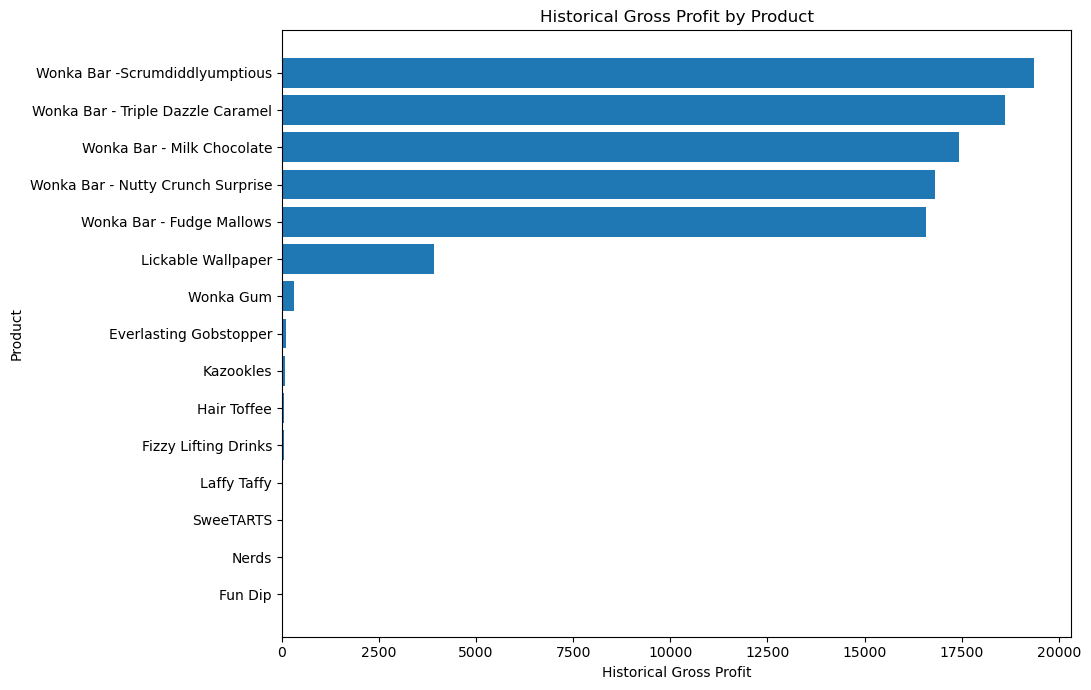

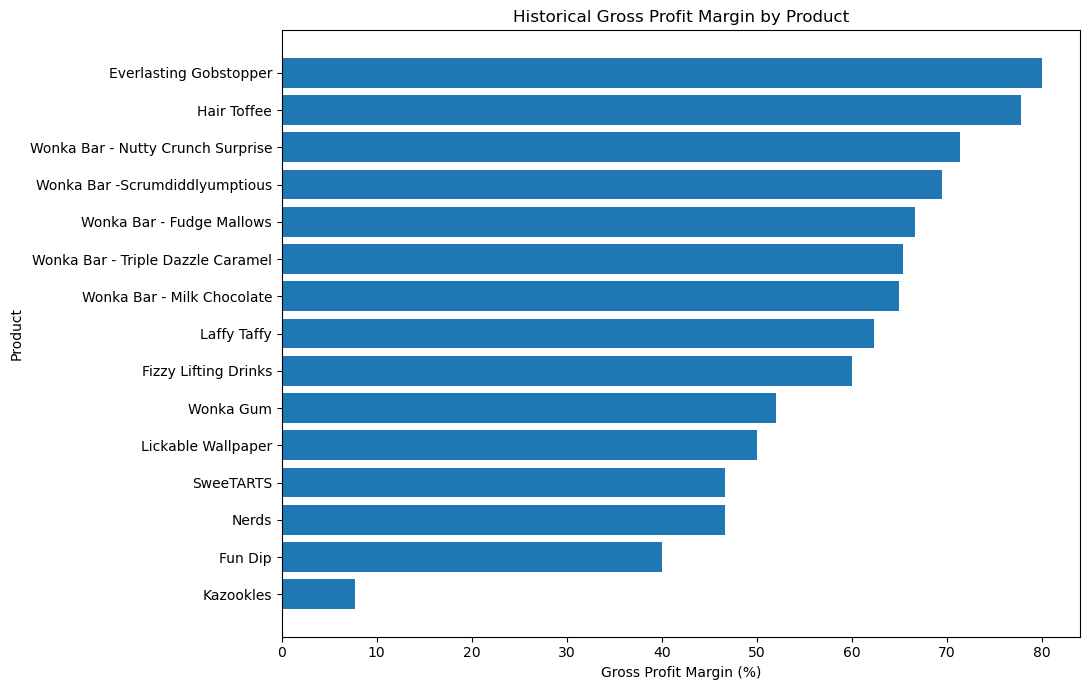

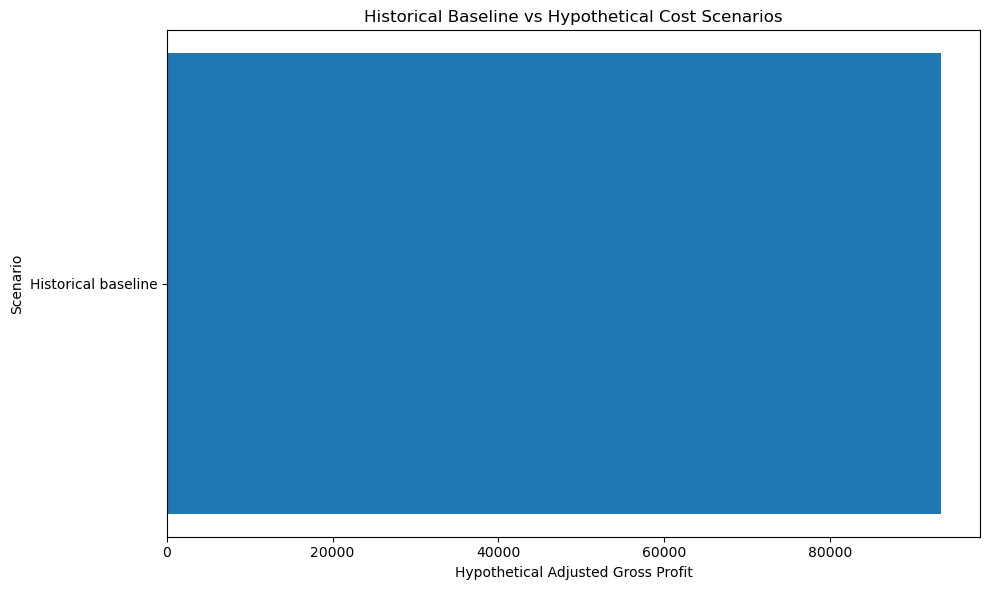

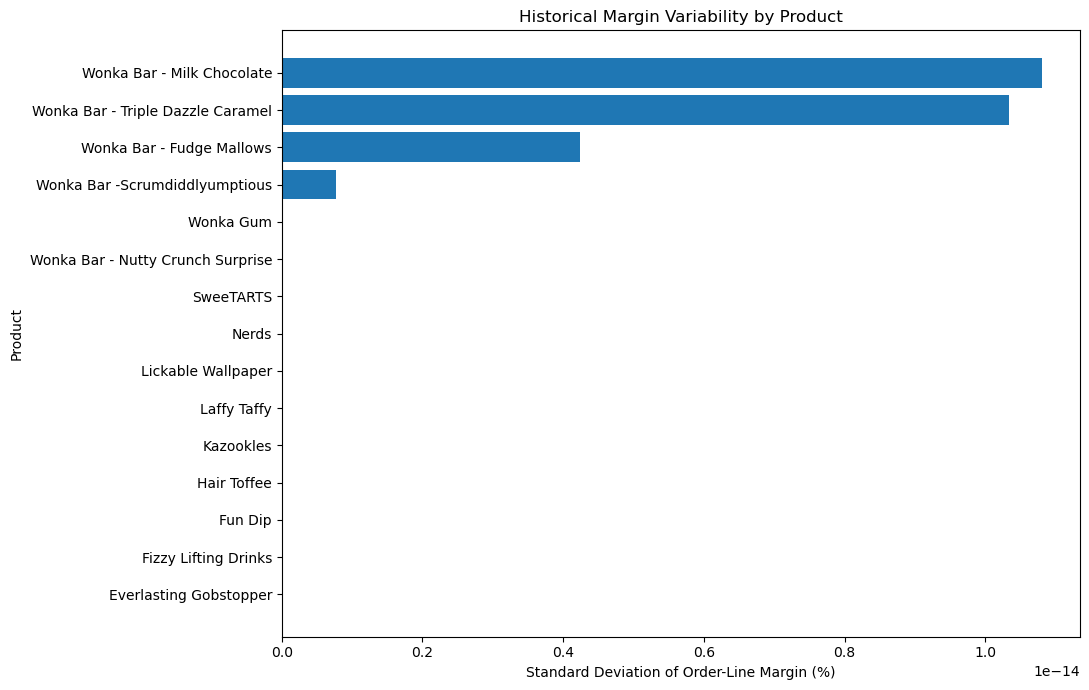

Phase 09 charts saved in: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures


In [35]:
# Create profit sensitivity charts
# Create and save historical profitability and hypothetical sensitivity charts

# Historical product gross profit chart
plot_profit = product_margin.sort_values(
    "Total_Gross_Profit",
    ascending=True
)

plt.figure(figsize=(11, 7))
plt.barh(
    plot_profit["Product Name"],
    plot_profit["Total_Gross_Profit"]
)
plt.xlabel("Historical Gross Profit")
plt.ylabel("Product")
plt.title("Historical Gross Profit by Product")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "phase09_historical_profit_by_product.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Product margin chart
plot_margin = product_margin.sort_values(
    "Gross_Profit_Margin_Pct",
    ascending=True
)

plt.figure(figsize=(11, 7))
plt.barh(
    plot_margin["Product Name"],
    plot_margin["Gross_Profit_Margin_Pct"]
)
plt.xlabel("Gross Profit Margin (%)")
plt.ylabel("Product")
plt.title("Historical Gross Profit Margin by Product")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "phase09_product_margin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Scenario-level hypothetical profit comparison
if not scenario_profit_impact_summary.empty:

    plot_scenarios = scenario_profit_impact_summary.sort_values(
        "Hypothetical_Adjusted_Gross_Profit",
        ascending=True
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        plot_scenarios["Scenario_Name"],
        plot_scenarios["Hypothetical_Adjusted_Gross_Profit"]
    )
    plt.xlabel("Hypothetical Adjusted Gross Profit")
    plt.ylabel("Scenario")
    plt.title("Historical Baseline vs Hypothetical Cost Scenarios")
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "phase09_hypothetical_profit_sensitivity.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

else:
    print("No scenario data available for sensitivity chart.")

# Margin variability chart
plot_stability = margin_stability.sort_values(
    "Std_Line_Margin_Pct",
    ascending=True
)

plt.figure(figsize=(11, 7))
plt.barh(
    plot_stability["Product Name"],
    plot_stability["Std_Line_Margin_Pct"]
)
plt.xlabel("Standard Deviation of Order-Line Margin (%)")
plt.ylabel("Product")
plt.title("Historical Margin Variability by Product")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "phase09_margin_variability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Phase 09 charts saved in:", FIGURES_DIR)

In [37]:
# Final verification cell
# Verify Phase 09 outputs and original dataset integrity

# Recalculate original CSV hash
final_source_hash = calculate_sha256(RAW_FILE)

# Verify source integrity
source_hash_check = final_source_hash == ORIGINAL_CSV_HASH

df_source_reloaded = pd.read_csv(RAW_FILE)

source_rows_check = len(df_source_reloaded) == original_row_count
source_columns_check = list(df_source_reloaded.columns) == original_columns

# Verify core outputs
required_phase09_files = [
    PROCESSED_DIR / "historical_sales_baseline.csv",
    PROCESSED_DIR / "historical_cost_baseline.csv",
    PROCESSED_DIR / "historical_gross_profit_baseline.csv",
    PROCESSED_DIR / "product_wise_profit_margin.csv",
    PROCESSED_DIR / "division_wise_profit_margin.csv",
    PROCESSED_DIR / "region_wise_profit_margin.csv",
    PROCESSED_DIR / "profit_variability_report.csv",
    PROCESSED_DIR / "margin_stability_proxy.csv",
    PROCESSED_DIR / "high_profit_product_ranking.csv",
    PROCESSED_DIR / "low_margin_product_risk_list.csv",
    FREIGHT_ASSUMPTIONS_FILE,
    MANUFACTURING_ASSUMPTIONS_FILE,
    PROCESSED_DIR / "cost_sensitivity_scenarios.csv",
    PROCESSED_DIR / "hypothetical_profit_impact.csv",
    PROCESSED_DIR / "profit_sensitivity_scenario_summary.csv",
    FIGURES_DIR / "phase09_historical_profit_by_product.png",
    FIGURES_DIR / "phase09_product_margin.png",
    FIGURES_DIR / "phase09_hypothetical_profit_sensitivity.png",
    FIGURES_DIR / "phase09_margin_variability.png"
]

phase09_integrity_checks = pd.DataFrame([
    {"Check": "Original CSV exists", "Passed": RAW_FILE.is_file()},
    {"Check": "Original CSV SHA-256 unchanged", "Passed": source_hash_check},
    {"Check": "Original row count preserved", "Passed": source_rows_check},
    {"Check": "Original columns preserved", "Passed": source_columns_check},
    *[
        {
            "Check": file_path.name,
            "Passed": file_path.is_file()
        }
        for file_path in required_phase09_files
    ]
])

display(phase09_integrity_checks)

PHASE09_INTEGRITY_FILE = (
    REPORTS_DIR / "Phase_09_Integrity_Report.csv"
)

phase09_integrity_checks.to_csv(
    PHASE09_INTEGRITY_FILE,
    index=False
)

all_phase09_checks_passed = phase09_integrity_checks["Passed"].all()

print("\nPHASE 09 INTEGRITY VERIFICATION")
print("Total checks:", len(phase09_integrity_checks))
print("Passed:", int(phase09_integrity_checks["Passed"].sum()))
print("Failed:", int((~phase09_integrity_checks["Passed"]).sum()))
print("All checks passed:", all_phase09_checks_passed)
print("Report saved:", PHASE09_INTEGRITY_FILE)

if all_phase09_checks_passed:
    print("SUCCESS: Phase 09 integrity verification completed.")
else:
    print("WARNING: Review failed checks before marking the phase complete.")
    display(
        phase09_integrity_checks[
            ~phase09_integrity_checks["Passed"]
        ]
    )

,Check,Passed
0,Original CSV exists,True
1,Original CSV SHA-256 unchanged,True
2,Original row count preserved,True
3,Original columns preserved,True
4,historical_sales_baseline.csv,True
5,historical_cost_baseline.csv,True
6,historical_gross_profit_baseline.csv,True
7,product_wise_profit_margin.csv,True
8,division_wise_profit_margin.csv,True
9,region_wise_profit_margin.csv,True



PHASE 09 INTEGRITY VERIFICATION
Total checks: 23
Passed: 23
Failed: 0
All checks passed: True
Report saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\profitability_sensitivity\Phase_09_Integrity_Report.csv
SUCCESS: Phase 09 integrity verification completed.
